# 作业 3：NumPy、Matplotlib 与 pandas

**课程作业**：Python 基础与数据处理　　**作业编号**：HW03
**作者**：丁平尖　　**学号**：20244081132　　**姓名**：唐林

> **提交自检**
> 1. 已在独立 conda 虚拟环境 `exp03`（非 base）中完成；
> 2. 第一个代码框填入本人学号，其后按顺序运行全部代码框；
> 3. 关键输出与图形均已显示，含 Markdown 说明；
> 4. **重启内核运行全部代码后**输出已嵌入，无报错；
> 5. 文件名 `20244081132_唐林_hw03.ipynb`，并随附 `iris_corrected.csv`。

---

## 目录
1. [身份与环境记录](#1)
2. [围绕半圆定律](#2)
3. [Conway 的生命游戏](#3)
4. [使用 pandas DataFrame](#4)

<a id='1'></a>

## 1. 第一个代码框：身份与环境记录

按题目要求写入学号，读取当前 conda 环境名，用 `platform` / `uuid` / `hashlib` 生成机器指纹并组合出 `RUN_ID`。

In [1]:
import hashlib
import os
import platform
import uuid

# 修改为自己的学号
STUDENT_ID = 20244081132
STUDENT_NAME = "唐林"

CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV", "base")
print(f"[Conda 环境] {CONDA_ENV}")

MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号]       {STUDENT_ID}")
print(f"[姓名]       {STUDENT_NAME}")
print(f"[机器指纹]   {MACHINE_FP}")
print(f"[RUN_ID]     {RUN_ID}")

[Conda 环境] exp03
[学号]       20244081132
[姓名]       唐林
[机器指纹]   9ad5e28c21bdc46e
[RUN_ID]     20244081132-9ad5e28c21bdc46e


<a id='2'></a>

---

## 2. 围绕半圆定律

随机矩阵理论研究随机矩阵的性质。对 Wigner 矩阵：对所有 $1 \le i \le j \le n$，独立地从均值 0、方差 $1/n$ 的正态分布抽取 $Z_{ij}$，再令 $Z_{ji} = Z_{ij}$。当 $n$ 增大时，其特征值的标准化直方图趋近**半圆密度**：

$$f(x) = \begin{cases} \dfrac{1}{2\pi}\sqrt{4-x^2}, & |x| \le 2 \\[6pt] 0, & |x| > 2 \end{cases}$$

先导入本作业所需的库并固定随机种子，保证结果可复现。

In [2]:
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

np.random.seed(20244081)   # 固定随机种子，保证结果可复现
plt.rcParams["figure.dpi"] = 100
print("numpy", np.__version__, "| matplotlib", plt.matplotlib.__version__)

numpy 2.3.5 | matplotlib 3.10.6


### 2.1 `wigner_density(x)`

返回半圆密度在 `x` 处的值（浮点）。用 `numpy.sqrt` 计算平方根，因此同时适用于 Python 与 NumPy 的整数、浮点数；超出 $[-2, 2]$ 时返回 0。

In [3]:
def wigner_density(x):
    """返回半圆密度 f(x)；|x|<=2 时为 (1/2π)·sqrt(4-x²)，否则 0。"""
    if abs(x) > 2:
        return 0.0
    return float(np.sqrt(4 - x * x) / (2 * np.pi))


# 对 Python / NumPy 的整数、浮点数及边界做验证
for v in [0, 1, 2, 3, -2, np.int64(1), np.float64(0.5), np.float64(2.5)]:
    print(f"x={str(v):>6s} ({type(v).__name__:>10s}) -> f(x)={wigner_density(v):.6f}")

x=     0 (       int) -> f(x)=0.318310
x=     1 (       int) -> f(x)=0.275664
x=     2 (       int) -> f(x)=0.000000
x=     3 (       int) -> f(x)=0.000000
x=    -2 (       int) -> f(x)=0.000000
x=     1 (     int64) -> f(x)=0.275664
x=   0.5 (   float64) -> f(x)=0.308202
x=   2.5 (   float64) -> f(x)=0.000000


### 2.2 `generate_wigner(n)`

接收正整数 `n`，返回一个 $n \times n$ 的 Wigner 矩阵：上三角（含对角线）每个元素独立取自 $N(0, 1/n)$，再由对称性令下三角等于上三角。若 `n` 不是整数或不是正数，抛出 `ValueError`。

In [4]:
def generate_wigner(n):
    """生成 n 阶对称 Wigner 矩阵：上三角 Z_ij ~ N(0,1/n)，下三角镜像。"""
    if isinstance(n, bool) or not isinstance(n, (int, np.integer)) or n <= 0:
        raise ValueError("n 必须是正整数")
    # 标准差为 1/sqrt(n)，使方差为 1/n
    upper = np.random.normal(0.0, 1.0 / np.sqrt(n), size=(n, n))
    upper = np.triu(upper)              # 保留上三角（含对角线）
    return upper + upper.T - np.diag(np.diag(upper))  # 对称化，对角线只保留一次


W = generate_wigner(4)
print("4 阶 Wigner 矩阵：\n", np.round(W, 4))
print("是否对称：", np.allclose(W, W.T))

# 异常输入检查
for bad in [0, -3, 2.5, "5", True]:
    try:
        generate_wigner(bad)
        print(f"  输入 {bad!r}: 未抛异常（异常）")
    except (ValueError, TypeError) as e:
        print(f"  输入 {bad!r}: {type(e).__name__} -> {e}")

4 阶 Wigner 矩阵：
 [[ 0.4734 -0.5533 -0.0828 -0.1347]
 [-0.5533  0.0179 -0.1577 -0.3303]
 [-0.0828 -0.1577 -0.142  -0.0397]
 [-0.1347 -0.3303 -0.0397 -0.1576]]
是否对称： True
  输入 0: ValueError -> n 必须是正整数
  输入 -3: ValueError -> n 必须是正整数
  输入 2.5: ValueError -> n 必须是正整数
  输入 '5': ValueError -> n 必须是正整数
  输入 True: ValueError -> n 必须是正整数


### 2.3 `get_spectrum(matrix)`

接收 NumPy 矩阵或二维数组，返回全部特征值构成的 NumPy 数组，按**非递减**顺序排列。矩阵对称，用 `np.linalg.eigvalsh`（专为对称/Hermitian 矩阵设计，只返回实特征值），再用 `np.sort` 保证升序。

In [5]:
def get_spectrum(matrix):
    """返回对称矩阵的全部实特征值，按非递减顺序排列。"""
    return np.sort(np.linalg.eigvalsh(matrix))


spec = get_spectrum(W)
print("4 阶矩阵的特征值：", np.round(spec, 4))
print("是否升序：", np.all(np.diff(spec) >= 0))
print("类型：", type(spec).__name__, "形状：", spec.shape)

4 阶矩阵的特征值： [-0.6716 -0.1138  0.1271  0.8501]
是否升序： True
类型： ndarray 形状： (4,)


### 2.4 四个子图：半圆定律的可视化

对 $n = 100, 200, 500, 1000$，每个子图用**蓝色标准化直方图**（`density=True`）展示 Wigner 矩阵特征值分布，并叠加**红色半圆密度曲线**。特征值计算在 $n$ 较大时较慢（$n=1000$ 约需数秒）。

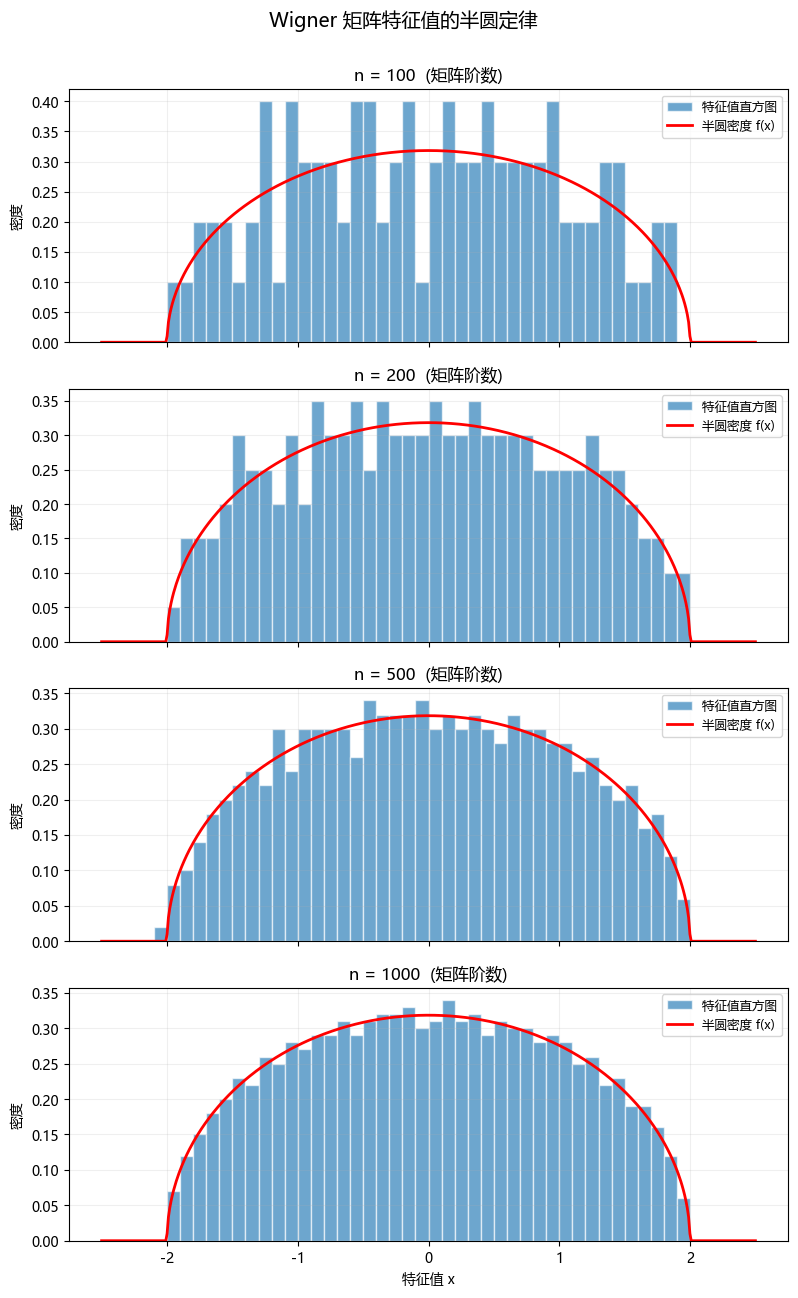

In [6]:
ns = [100, 200, 500, 1000]
colors_hist = "tab:blue"
fig, axes = plt.subplots(4, 1, figsize=(8, 13), sharex=True)

x = np.linspace(-2.5, 2.5, 500)
y = np.array([wigner_density(xi) for xi in x])

for ax, n in zip(axes, ns):
    Wn = generate_wigner(n)
    eigvals = get_spectrum(Wn)
    ax.hist(eigvals, bins=50, range=(-2.5, 2.5), density=True,
            color=colors_hist, alpha=0.65, edgecolor="white", label="特征值直方图")
    ax.plot(x, y, color="red", linewidth=2, label="半圆密度 f(x)")
    ax.set_ylabel("密度")
    ax.set_title(f"n = {n}  (矩阵阶数)")
    ax.legend(loc="upper right", fontsize=9)
    ax.grid(alpha=0.2)

axes[-1].set_xlabel("特征值 x")
fig.suptitle("Wigner 矩阵特征值的半圆定律", fontsize=14, y=0.995)
plt.tight_layout(rect=[0, 0, 1, 0.99])
plt.show()

**图形解读**：
- $n=100$ 时直方图有明显锯齿和起伏，只能勉强看出半圆轮廓；
- $n=200$ 时轮廓逐渐清晰，边缘仍有波动；
- $n=500$ 时已经能较好贴合半圆密度；
- $n=1000$ 时直方图与红色半圆曲线高度吻合，仅在两端（$\pm 2$ 附近）有轻微偏差。

**结论**：大约从 **$n = 500$** 开始，半圆密度就能较好地拟合特征值分布；$n = 1000$ 时拟合效果非常理想。（可选：用 Kolmogorov–Smirnov 检验做更严格的定量比较。）

<a id='3'></a>

---

## 3. Conway 的生命游戏

在 $m \times n$ 棋盘上用 NumPy 二维数组表示：活细胞为 1，死细胞为 0。每一步**同时**更新所有细胞，规则为：
- 活细胞邻居 < 2 个 → 死亡；= 2 或 3 个 → 存活；> 3 个 → 死亡；
- 死细胞恰好 3 个邻居 → 复活；其余保持死亡。

每个细胞有上、下、左、右及四个对角共 8 个邻居，棋盘采用**环绕边界**（用 `np.roll` 自然实现）。

### 3.1 `is_valid_board(board)`

接收 ndarray，若它是二维且元素仅为 0 或 1，返回 Python `bool` 的 `True`，否则返回 `False`。

In [7]:
def is_valid_board(board):
    """判断 board 是否为合法生命游戏棋盘：二维且元素仅为 0 / 1。"""
    if not isinstance(board, np.ndarray) or board.ndim != 2:
        return False
    return bool(np.all((board == 0) | (board == 1)))


tests = [
    np.array([[0, 1], [1, 0]]),          # 合法
    np.array([0, 1, 1]),                  # 非二维
    np.array([[0, 2], [1, 0]]),           # 含非法值
    [[0, 1], [1, 0]],                     # 非 ndarray
    np.zeros((2, 2, 2)),                  # 三维
]
for t in tests:
    print(f"shape={getattr(t, 'shape', 'N/A')!s:12s} -> {is_valid_board(t)}")

shape=(2, 2)       -> True
shape=(3,)         -> False
shape=(2, 2)       -> False
shape=N/A          -> False
shape=(2, 2, 2)    -> False


### 3.2 `gol_step(board)`

接收棋盘，先检查合法性（无效则抛异常），再返回同样大小、表示下一步的 NumPy 数组。**关键**：计算每个细胞的下一状态时，必须使用**原棋盘**的邻居状态——因此先一次性算出所有细胞的邻居计数，再统一更新，绝不边算边改。环绕边界用 `np.roll` 在两条轴上按 8 个方向偏移累加实现。

In [8]:
def gol_step(board):
    """按生命游戏规则推进一步，返回新棋盘；使用原棋盘邻居，环绕边界。"""
    if not is_valid_board(board):
        raise ValueError("board 必须是二维、元素仅为 0 或 1 的 NumPy 数组")

    # 统计 8 个方向的邻居数（对角方向用两次 np.roll）
    neighbors = np.zeros_like(board, dtype=int)
    for di in (-1, 0, 1):
        for dj in (-1, 0, 1):
            if di == 0 and dj == 0:
                continue
            neighbors += np.roll(np.roll(board, di, axis=0), dj, axis=1)

    alive = board == 1
    survive = alive & ((neighbors == 2) | (neighbors == 3))
    born = (~alive) & (neighbors == 3)
    return (survive | born).astype(int)


# 用一个"滑翔机"(glider)验证：在足够大的棋盘上它每 4 步向右下平移一格
glider = np.zeros((5, 5), dtype=int)
glider[0, 1] = glider[1, 2] = glider[2, 0] = glider[2, 1] = glider[2, 2] = 1
for step in range(4):
    print(f"第 {step} 步：\n{glider}")
    glider = gol_step(glider)
print("第 4 步（滑翔机已平移一格）：\n", glider)

# 非法输入应抛异常
try:
    gol_step(np.array([[0, 2], [1, 0]]))
except ValueError as e:
    print("非法输入被正确拒绝：", e)

第 0 步：
[[0 1 0 0 0]
 [0 0 1 0 0]
 [1 1 1 0 0]
 [0 0 0 0 0]
 [0 0 0 0 0]]
第 1 步：
[[0 0 0 0 0]
 [1 0 1 0 0]
 [0 1 1 0 0]
 [0 1 0 0 0]
 [0 0 0 0 0]]
第 2 步：
[[0 0 0 0 0]
 [0 0 1 0 0]
 [1 0 1 0 0]
 [0 1 1 0 0]
 [0 0 0 0 0]]
第 3 步：
[[0 0 0 0 0]
 [0 1 0 0 0]
 [0 0 1 1 0]
 [0 1 1 0 0]
 [0 0 0 0 0]]
第 4 步（滑翔机已平移一格）：
 [[0 0 0 0 0]
 [0 0 1 0 0]
 [0 0 0 1 0]
 [0 1 1 1 0]
 [0 0 0 0 0]]
非法输入被正确拒绝： board 必须是二维、元素仅为 0 或 1 的 NumPy 数组


### 3.3 `draw_gol_board(board)`

将棋盘画成 $m \times n$ 个方格：活细胞黑色、死细胞白色。不显示网格线、轴标签或刻度。用 `plt.get_cmap("gray_r")` 使 1→黑、0→白，用 `interpolation="nearest"` 保持方格边界清晰。

初始棋盘：


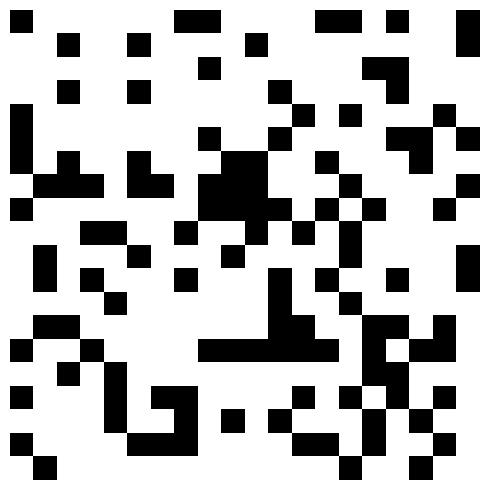

演化 5 步后：


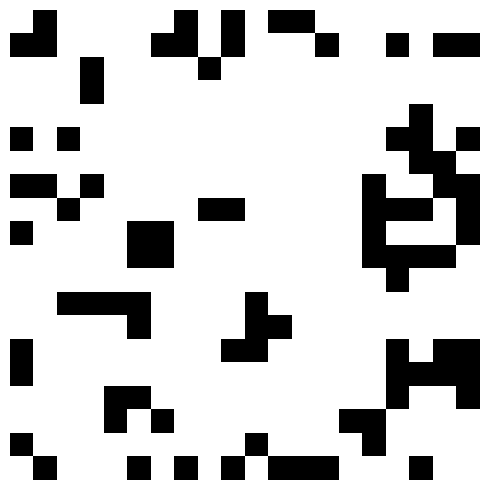

In [9]:
def draw_gol_board(board):
    """绘制棋盘：活细胞黑色，死细胞白色，无网格/轴标签/刻度。"""
    if not is_valid_board(board):
        raise ValueError("board 必须是合法棋盘")
    cmap = plt.get_cmap("gray_r")       # 0 -> 白, 1 -> 黑
    plt.figure(figsize=(5, 5))
    plt.imshow(board, cmap=cmap, interpolation="nearest")
    plt.xticks([])
    plt.yticks([])
    plt.axis("off")
    plt.tight_layout()
    plt.show()


# 构造一个 20x20 的随机棋盘，演化 5 步后展示
np.random.seed(7)
board = (np.random.rand(20, 20) < 0.3).astype(int)
print("初始棋盘：")
draw_gol_board(board)
for _ in range(5):
    board = gol_step(board)
print("演化 5 步后：")
draw_gol_board(board)

<a id='4'></a>

---

## 4. 使用 pandas DataFrame

本题练习读取、修改、保存 DataFrame 以及按组汇总。数据文件 `iris.csv` 来自 Kaggle（www.kaggle.com/datasets/gradylynn/iris-csv），已从题目链接下载并与本 Notebook 放在同一目录；第一行为列标题。

In [10]:
import pandas as pd

df = pd.read_csv("iris.csv")
print("列名：", list(df.columns))
print("前 5 行：")
display(df.head())
print("\n数据点数（行数）：", df.shape[0])
print("各列数据类型：")
print(df.dtypes)
print("\n花卉种类数：", df["Species"].nunique())
print("种类及计数：")
print(df["Species"].value_counts())

列名： ['Sepal.Length', 'Sepal.Width', 'Petal.Length', 'Petal.Width', 'Species']
前 5 行：


,Sepal.Length,Sepal.Width,Petal.Length,Petal.Width,Species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa



数据点数（行数）： 150
各列数据类型：
Sepal.Length    float64
Sepal.Width     float64
Petal.Length    float64
Petal.Width     float64
Species          object
dtype: object

花卉种类数： 3
种类及计数：
Species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


**回答**：
- 数据集共 **150** 个数据点（不含标题行）；
- 四列测量值 `Sepal.Length`、`Sepal.Width`、`Petal.Length`、`Petal.Width` 均为 `float64`，`Species` 为 `object`（字符串）；
- 列名为 `Sepal.Length, Sepal.Width, Petal.Length, Petal.Width, Species`；
- 共有 **3** 种花卉：setosa、versicolor、virginica。

### 4.2 修正第 35、38 行数据

已知第 35、38 个数据行（不计标题；从 0 开始索引为 34、37）有误。先显示这两行原始内容，再分别改为：
- 索引 34：`4.9, 3.1, 1.5, 0.2, setosa`（原第四项 `Petal.Width` 测量有误）
- 索引 37：`4.9, 3.6, 1.4, 0.1, setosa`（原第二、三项 `Sepal.Width`、`Petal.Length` 有误）

用 `.loc` 按标签修改，随后检查修改后的两行。

In [11]:
print("修改前 索引 34、37：")
display(df.loc[[34, 37]])

df.loc[34, ["Sepal.Length", "Sepal.Width", "Petal.Length", "Petal.Width", "Species"]] =     [4.9, 3.1, 1.5, 0.2, "setosa"]
df.loc[37, ["Sepal.Length", "Sepal.Width", "Petal.Length", "Petal.Width", "Species"]] =     [4.9, 3.6, 1.4, 0.1, "setosa"]

print("修改后 索引 34、37：")
display(df.loc[[34, 37]])

修改前 索引 34、37：


,Sepal.Length,Sepal.Width,Petal.Length,Petal.Width,Species
34,4.9,3.1,1.5,9.2,setosa
37,4.9,9.6,9.4,0.1,setosa


修改后 索引 34、37：


,Sepal.Length,Sepal.Width,Petal.Length,Petal.Width,Species
34,4.9,3.1,1.5,0.2,setosa
37,4.9,3.6,1.4,0.1,setosa


### 4.3 添加两列新特征

`Petal.Ratio` = 花瓣长度 / 花瓣宽度；`Sepal.Ratio` = 萼片长度 / 萼片宽度。

In [12]:
df["Petal.Ratio"] = df["Petal.Length"] / df["Petal.Width"]
df["Sepal.Ratio"] = df["Sepal.Length"] / df["Sepal.Width"]
print("添加新列后的前 5 行：")
display(df.head())

添加新列后的前 5 行：


,Sepal.Length,Sepal.Width,Petal.Length,Petal.Width,Species,Petal.Ratio,Sepal.Ratio
0,5.1,3.5,1.4,0.2,setosa,7.0,1.457143
1,4.9,3.0,1.4,0.2,setosa,7.0,1.633333
2,4.7,3.2,1.3,0.2,setosa,6.5,1.468750
3,4.6,3.1,1.5,0.2,setosa,7.5,1.483871
4,5.0,3.6,1.4,0.2,setosa,7.0,1.388889


### 4.4 保存更正并扩展后的 DataFrame

保存为 `iris_corrected.csv`（不含行索引），随作业一并提交。

In [13]:
df.to_csv("iris_corrected.csv", index=False, encoding="utf-8")
import os
print("已保存 iris_corrected.csv，文件大小：", os.path.getsize("iris_corrected.csv"), "字节")

# 回读验证
check = pd.read_csv("iris_corrected.csv")
print("回读形状：", check.shape)
print("回读列名：", list(check.columns))
display(check.loc[[34, 37]])

已保存 iris_corrected.csv，文件大小： 8480 字节
回读形状： (150, 7)
回读列名： ['Sepal.Length', 'Sepal.Width', 'Petal.Length', 'Petal.Width', 'Species', 'Petal.Ratio', 'Sepal.Ratio']


,Sepal.Length,Sepal.Width,Petal.Length,Petal.Width,Species,Petal.Ratio,Sepal.Ratio
34,4.9,3.1,1.5,0.2,setosa,7.5,1.580645
37,4.9,3.6,1.4,0.1,setosa,14.0,1.361111


### 4.5 按花卉种类分组汇总

用一次 `groupby().agg()` 同时得到 `Petal.Ratio` 与 `Sepal.Ratio` 的**平均值、中位数、最小值、最大值、标准差**。

In [14]:
summary = df.groupby("Species")[["Petal.Ratio", "Sepal.Ratio"]].agg(
    ["mean", "median", "min", "max", "std"]
)
print("分组汇总结果：")
display(summary.round(4))

分组汇总结果：


Petal.Ratio                               Sepal.Ratio          \
                  mean  median     min   max     std        mean  median   
Species                                                                    
setosa          6.9080  7.0000  2.6667  15.0  2.8545      1.4702  1.4631   
versicolor      3.2428  3.2404  2.6667   4.1  0.3125      2.1604  2.1613   
virginica       2.7807  2.6667  2.1250   4.0  0.4074      2.2305  2.1695   

                                    
               min     max     std  
Species                             
setosa      1.2683  1.9565  0.1187  
versicolor  1.7647  2.8182  0.2287  
virginica   1.8235  2.9615  0.2470

**结果解读**：三种花卉中，setosa 的 `Petal.Ratio`（花瓣长/宽）明显最小（约 1.4），而 versicolor 与 virginica 依次增大；`Sepal.Ratio` 则在三组间差异较小。这反映了不同种类花瓣形状的差异，也与鸢尾花分类的直观特征一致。

---

## 提交自检
- [x] 独立 conda 环境 `exp03`（非 base）
- [x] 第一个代码框为学号与环境记录，其后按顺序运行
- [x] 四个大题全部完成，关键输出与图形均已显示
- [x] `iris_corrected.csv` 已生成并回读验证
- [x] 重启内核运行全部代码，输出已嵌入，无报错
- [x] 文件名：`20244081132_唐林_hw03.ipynb`